In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb

In [ ]:
df=pd.read_csv('/content/Telco-Customer-Churn.csv')
df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


In [ ]:
df.shape

(7043, 21)

In [ ]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [ ]:
df.isna().sum().sum()

np.int64(0)

In [ ]:
df.drop('customerID',axis=1,inplace=True)

In [ ]:
numerical_columns=['tenure','MonthlyCharges','TotalCharges']

for col in df.columns:
  if col in numerical_columns:
    pass
  else:
    print(col,'-->',df[col].unique())
    print('------------')

gender --> ['Female' 'Male']
------------
SeniorCitizen --> [0 1]
------------
Partner --> ['Yes' 'No']
------------
Dependents --> ['No' 'Yes']
------------
PhoneService --> ['No' 'Yes']
------------
MultipleLines --> ['No phone service' 'No' 'Yes']
------------
InternetService --> ['DSL' 'Fiber optic' 'No']
------------
OnlineSecurity --> ['No' 'Yes' 'No internet service']
------------
OnlineBackup --> ['Yes' 'No' 'No internet service']
------------
DeviceProtection --> ['No' 'Yes' 'No internet service']
------------
TechSupport --> ['No' 'Yes' 'No internet service']
------------
StreamingTV --> ['No' 'Yes' 'No internet service']
------------
StreamingMovies --> ['No' 'Yes' 'No internet service']
------------
Contract --> ['Month-to-month' 'One year' 'Two year']
------------
PaperlessBilling --> ['Yes' 'No']
------------
PaymentMethod --> ['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']
------------
Churn --> ['No' 'Yes']
------------


In [ ]:
df['TotalCharges']=df['TotalCharges'].replace(' ','0.0')

In [ ]:
df['TotalCharges']=df['TotalCharges'].astype(float)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-null   object 


In [ ]:
df['Churn'].value_counts()

,count
Churn,
No,5174
Yes,1869


**EDA(Exploratory Data Analysis)**

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-null   object 


In [ ]:
df.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [ ]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


**Numerical feature analysis**

In [ ]:
def plt_histogram(df,column_name):
  plt.figure(figsize=(5,3))
  sb.histplot(df[column_name],kde=True)
  plt.title(f"distibution of {column_name}")

  #calculate mean and median for the columns
  col_mean=df[column_name].mean()
  col_median=df[column_name].median()

  #
  plt.axvline(col_mean,color='red',linestyle='--',label='mean',linewidth=1)
  plt.axvline(col_median,color='red',linestyle='--',label='median',linewidth=1)


  plt.legend()
  plt.show()

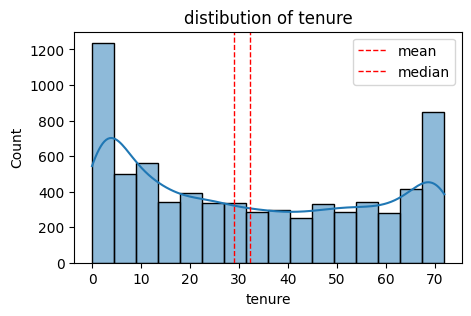

In [ ]:
plt_histogram(df,"tenure")

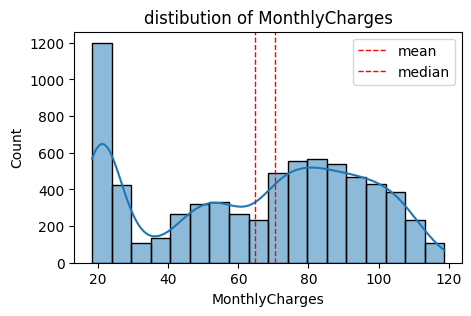

In [ ]:
plt_histogram(df,"MonthlyCharges")

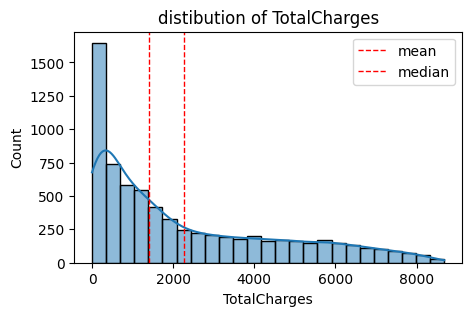

In [ ]:
plt_histogram(df,"TotalCharges")

**Box Plot for Numerical features**

In [ ]:
def box_plot(df,column_name):
  plt.figure(figsize=(5,3))
  sb.boxplot(y=df[column_name])
  plt.title(f"Boxplot of {column_name}")
  plt.xlabel(column_name)
  plt.show()

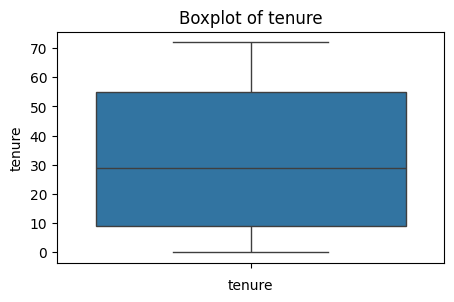

In [ ]:
box_plot(df,'tenure')

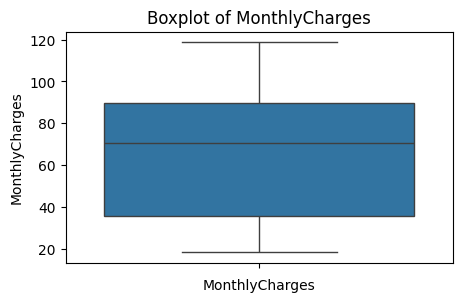

In [ ]:
box_plot(df,'MonthlyCharges')

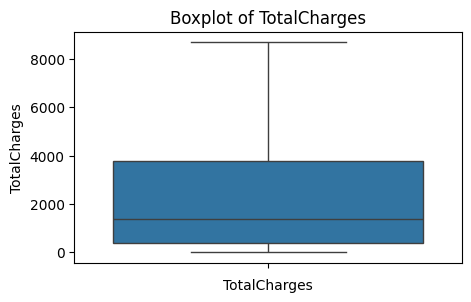

In [ ]:
box_plot(df,"TotalCharges")

**correlation Heatmap for Numerical Columns**

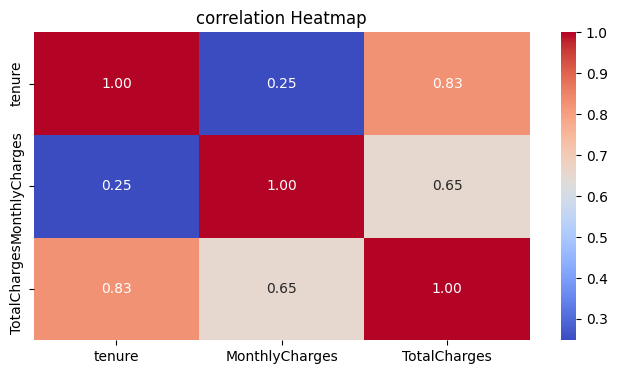

In [ ]:
plt.figure(figsize=(8,4))
sb.heatmap(df[['tenure','MonthlyCharges','TotalCharges']].corr(),annot=True,cmap='coolwarm',fmt='.2f')
plt.title('correlation Heatmap')
plt.show()


In [ ]:
df_categorical_columns=[]

for col in df.columns:
  if df[col].dtypes=='object':
    df_categorical_columns.append(col)

df_categorical_columns=['SeniorCitizen']+df_categorical_columns

In [ ]:
df_categorical_columns

['SeniorCitizen',
 'gender',
 'Partner',
 'Dependents',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'Churn']

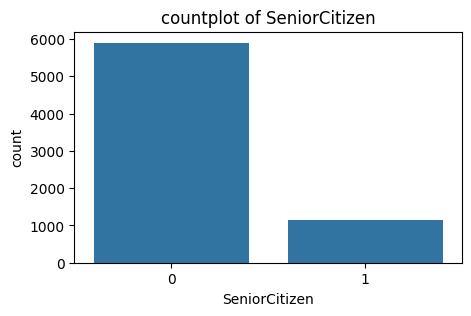

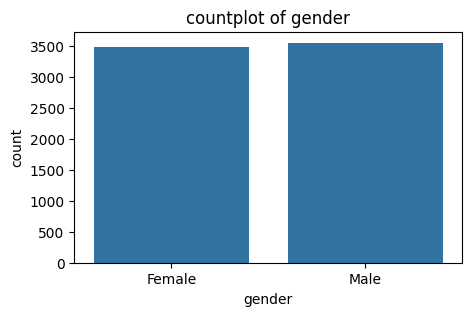

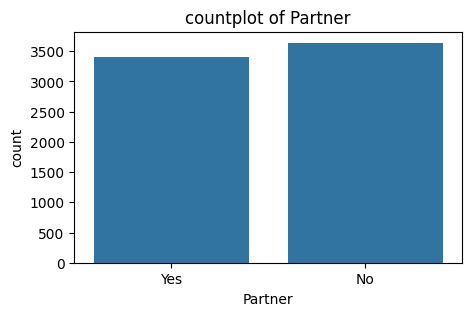

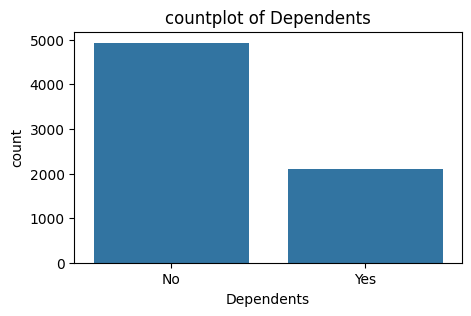

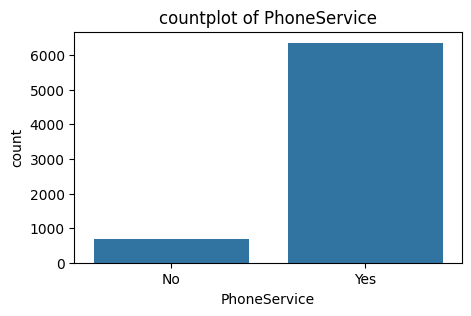

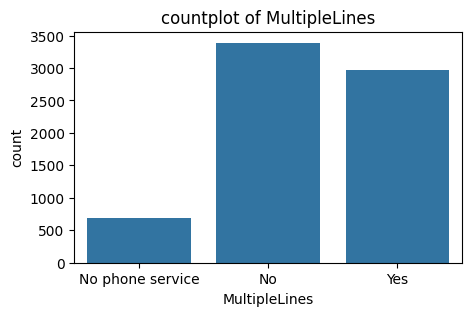

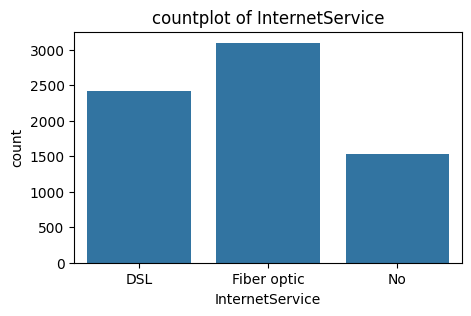

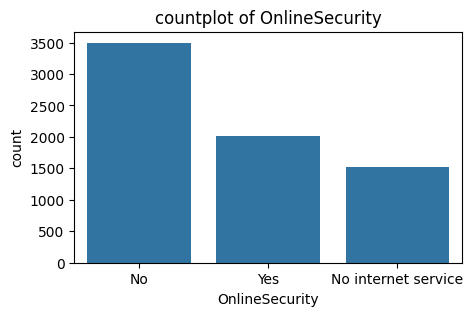

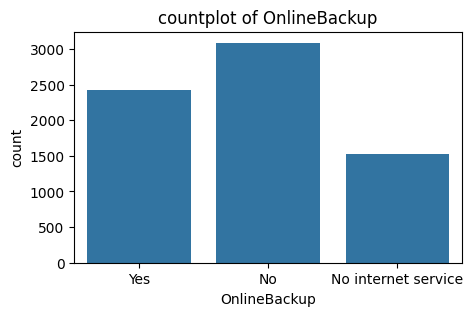

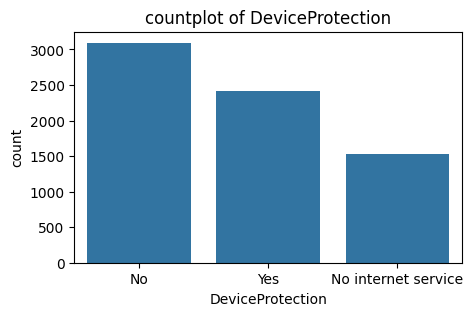

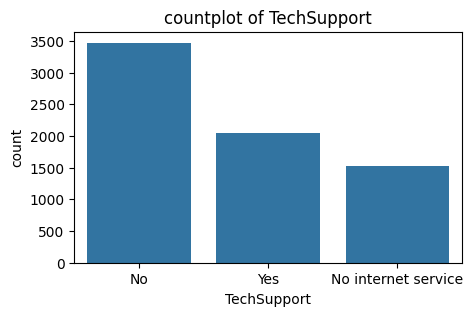

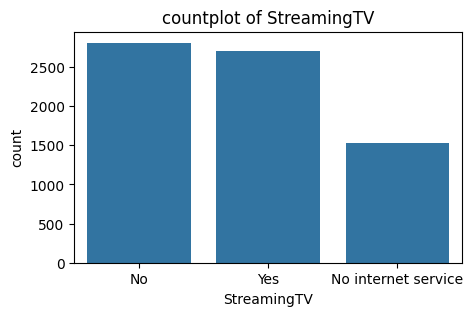

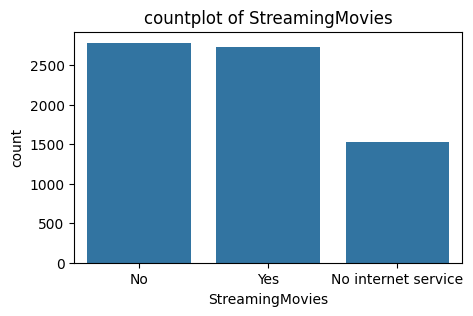

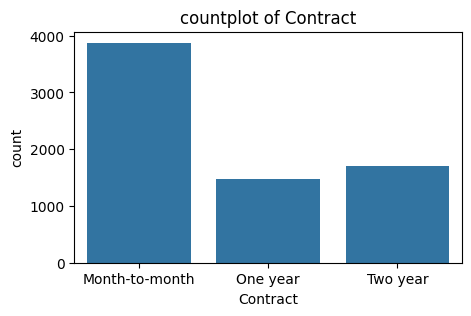

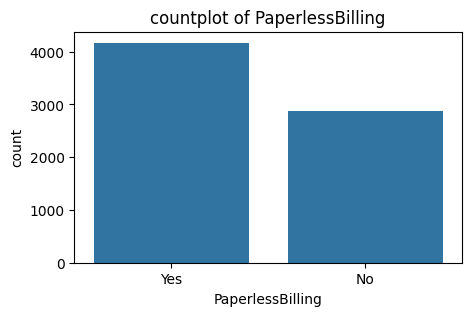

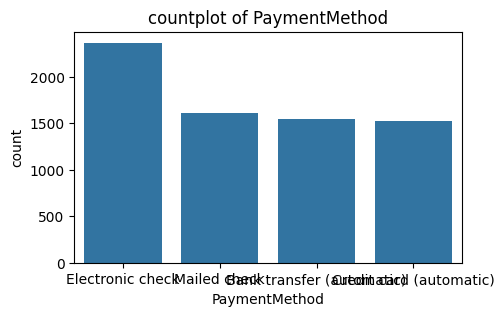

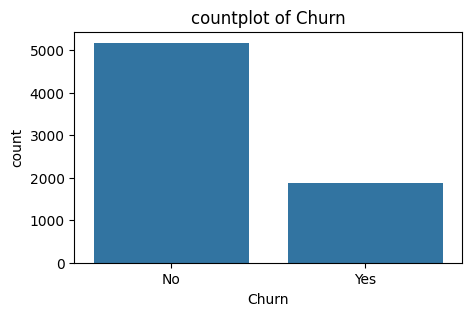

In [ ]:
for col in df_categorical_columns:
  plt.figure(figsize=(5,3))
  sb.countplot(x=df[col])
  plt.title(f"countplot of {col}")
  plt.show()

**Data Preprocessing**

In [ ]:
df.head(3)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


Label Encoding for Target column

In [ ]:
df['Churn']=df['Churn'].replace({'Yes':1,'No':0})

/tmp/ipykernel_1831/312515965.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['Churn']=df['Churn'].replace({'Yes':1,'No':0})


In [ ]:
df

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50,0
7039,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90,0
7040,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,0
7041,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.60,1


In [ ]:
df['Churn'].value_counts()

,count
Churn,
0,5174
1,1869


Label Encoding for categorical columns

In [ ]:
from sklearn.preprocessing import LabelEncoder

In [ ]:
for col in df.columns:
  if df[col].dtypes=='object':
    le=LabelEncoder()
    df[col]=le.fit_transform(df[col])

In [ ]:
df.head(3)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,0,1,0,1,0,1,0,0,2,0,0,0,0,0,1,2,29.85,29.85,0
1,1,0,0,0,34,1,0,0,2,0,2,0,0,0,1,0,3,56.95,1889.50,0
2,1,0,0,0,2,1,0,0,2,2,0,0,0,0,0,1,3,53.85,108.15,1


**Training and testing Split**

In [ ]:
x=df.drop('Churn',axis=1)

In [ ]:
y=df['Churn']

In [ ]:
x.shape

(7043, 19)

In [ ]:
y.shape

(7043,)

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

**Synthetic minority oversampling Technique**

In [ ]:
from imblearn.over_sampling import SMOTE

In [ ]:
smote=SMOTE(random_state=42)

In [ ]:
x_train_smote,y_train_smote=smote.fit_resample(x_train,y_train)

In [ ]:
y_train_smote.value_counts()

,count
Churn,
0,4138
1,4138


**Model Training**

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

In [ ]:
models={"Decision Tree":DecisionTreeClassifier(random_state=42),
        "Random Forest":RandomForestClassifier(random_state=42),
        "XG BOOST":XGBClassifier(random_state=42)}

In [ ]:
from sklearn.model_selection import cross_val_score

In [ ]:
cv_scores={}

for model_name,model in models.items():
  print(f"training {model_name} with default parameter")
  scores=cross_val_score(model,x_train_smote,y_train_smote,cv=5,scoring='accuracy')
  cv_scores[model_name]=scores
  print(f"{model_name} cross_val_accuracy:{np.mean(scores):.2f}")
  print('---------------------------------')

training Decision Tree with default parameter
Decision Tree cross_val_accuracy:0.78
---------------------------------
training Random Forest with default parameter
Random Forest cross_val_accuracy:0.84
---------------------------------
training XG BOOST with default parameter
XG BOOST cross_val_accuracy:0.83
---------------------------------


**Random Forest gives the highest accuracy with default parameter**

In [ ]:
cv_scores

{'Decision Tree': array([0.68297101, 0.71299094, 0.82175227, 0.83564955, 0.83564955]),
 'Random Forest': array([0.72524155, 0.77824773, 0.90513595, 0.89425982, 0.90090634]),
 'XG BOOST': array([0.71135266, 0.74984894, 0.90271903, 0.89607251, 0.89667674])}

In [ ]:
rfc=RandomForestClassifier(random_state=42)

In [ ]:
rfc.fit(x_train_smote,y_train_smote)

RandomForestClassifier(random_state=42)

**Model Evaluation**

In [ ]:
from sklearn.metrics import *

In [ ]:
y_pred=rfc.predict(x_test)
y_pred

array([1, 0, 0, ..., 0, 0, 0])

In [ ]:
y_test.value_counts()

,count
Churn,
0,1036
1,373


In [ ]:
print('accuracy_score:\n',accuracy_score(y_test,y_pred))
print('-------------------------------------')

print('confusion_matrix:\n',confusion_matrix(y_test,y_pred))
print('-------------------------------------')

print('classification_report:\n',classification_report(y_test,y_pred))
print('-------------------------------------')

accuracy_score:
 0.7785663591199432
-------------------------------------
confusion_matrix:
 [[878 158]
 [154 219]]
-------------------------------------
classification_report:
               precision    recall  f1-score   support

           0       0.85      0.85      0.85      1036
           1       0.58      0.59      0.58       373

    accuracy                           0.78      1409
   macro avg       0.72      0.72      0.72      1409
weighted avg       0.78      0.78      0.78      1409

-------------------------------------


**Conclusion**:

Model Performance: Random Forest emerged as the best-performing classifier during 5-fold cross-validation, achieving an overall accuracy of 84%, outperforming XGBoost (83%) and Decision Tree (78%).


Business Impact: By successfully identifying customers at high risk of churning, the telecom business can proactively deploy targeted retention strategies, reduced-rate offers, or customer support interventions to decrease revenue loss.


Pipeline Integrity: Balancing the dataset using SMOTE on the training set enabled the model to maintain strong predictive capability on minority churn instances without overfitting to the test data.

**Challenges Faced & Solutions**:


Data Quality & Hidden Missing Values:

Challenge: The TotalCharges column contained blank whitespace strings rather than standard null values, which caused data type mismatches (parsed as object instead of float64).

Solution: Identified non-numeric entries during initial data profiling, replaced whitespace strings with standard numeric values (0.0), and cast the column to float64.




Severe Class Imbalance:

Challenge: The target variable Churn was heavily skewed (~73% retained vs. ~27% churned), which would lead standard classifiers to bias toward predicting the majority non-churn class.

Solution: Applied SMOTE (Synthetic Minority Over-sampling Technique) on the training dataset to generate synthetic samples for the minority class.






Preventing Data Leakage:

Challenge: Applying oversampling techniques like SMOTE before splitting data can cause synthetic data points derived from validation/test data to leak into the training split.

Solution: Strictly performed train_test_split before running SMOTE to ensure the test set remained strictly unseen, real-world data.